In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import tifffile
from PIL import Image
import numpy as np
from scipy.optimize import curve_fit
from scipy.integrate import cumulative_trapezoid
from scipy.signal import savgol_filter
import pandas as pd
import matplotlib.transforms as mtransforms
from statsmodels.nonparametric.smoothers_lowess import lowess
import cmcrameri.cm as cm

from matplotlib.patches import Rectangle
from matplotlib.patches import Polygon

import analysis_functions as afn

In [2]:
def double_gaussian(x, x1, w1, A1, x2, w2, A2):
    peak_neg = A1 * np.exp(-((x - x1) / w1)**2)
    peak_pos = A2 * np.exp(-((x - x2) / w2)**2)
    return peak_neg + peak_pos

In [3]:
def get_lineouts(times, bg):
    positions = []
    lineouts = []
    for t in times:
        y1, lo1 = afn.plot_vlineout_streak(t_ns = t - px_to_ns, ext = ext, image =streak, return_data = True, plot = False, output = f'streak_images/lineouts/linout_t={t}ns.jpg')
        y2, lo2 = afn.plot_vlineout_streak(t_ns = t, ext = ext, image =streak, return_data = True, plot = False, output = f'streak_images/lineouts/linout_t={t}ns.jpg')
        y3, lo3 = afn.plot_vlineout_streak(t_ns = t + px_to_ns, ext = ext, image =streak, return_data = True, plot = False, output = f'streak_images/lineouts/linout_t={t}ns.jpg')
        lineouts.append(np.average([lo1, lo2, lo3], axis = 0))
        positions.append(np.average([y1, y2, y3], axis = 0))
    positions = np.array(positions)
    lineouts = np.array(lineouts, dtype=object)
    if bg.all() != 0:
        print('background subtracting...')
        lineouts = (lineouts-background)/background
    return positions, lineouts

In [4]:
with Image.open('data_shot3_raw/streak/z4290leg1_laserstreak_preshot-nr.tif') as img:
    streak_pre_nr = np.array(img)
with Image.open('data_shot3_raw/streak/z4290leg1_laserstreak_preshot-r.tif') as img:
    streak_pre_r = np.array(img)   
with Image.open('data_shot3_raw/streak/z4290leg1_laserstreak.tif') as img:
    streak = np.array(img)   

calib = pd.read_csv('streak_calib.csv')

In [5]:
px_to_mm = calib['value'].values[0]
px_to_ns = calib['value'].values[1]
print(px_to_ns*3)

cmax = np.percentile(streak, 99)

0.1004481480808545


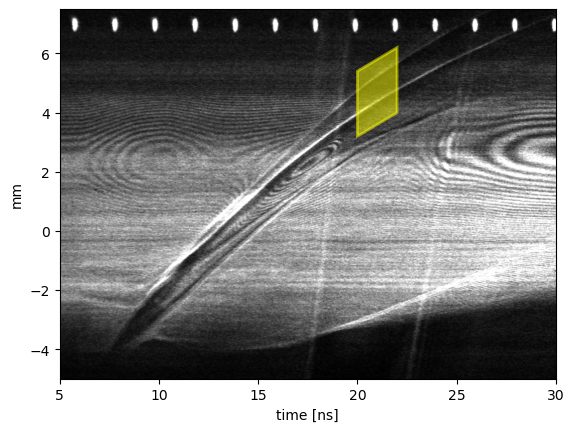

In [6]:
fig, ax = plt.subplots()

extent_x = streak.shape[1] * px_to_ns
extent_y = streak.shape[0] * px_to_mm
ext=[0, extent_x, -extent_y/2, extent_y/2]

plt.imshow(streak, cmap = 'grey', extent=ext, aspect='auto')
plt.clim(0, cmax)
plt.xlabel('time [ns]')
plt.ylabel('mm')

plt.xlim(5, 30)
# plt.xlim(18, 24)
plt.ylim(-5,7.5)

x0, y0 = 20, 3.2   # bottom-left corner
w, h   = 2, 3   # width/height (vertical sides stay vertical)
dx     = 0.8       # horizontal shift of the top edge vs bottom edge

# Vertices in order (left-bottom, right-bottom, right-top, left-top)
verts = [
    (x0,       y0),        # left bottom
    (x0 + w,   y0 + dx),        # right bottom (vertical side x = x0+w)
    (x0 + w,   y0 + h),    # right top
    (x0,  y0 + h - dx),    # left top shifted by dx -> non-horizontal top/bottom edges
]

poly = Polygon(verts, closed=True, color = 'yellow', alpha = 0.5, linewidth=2)
ax.add_patch(poly)

# ax.set_aspect("equal", adjustable="box")

plt.savefig('streak_images/zfs/streak_zoom_ROI.jpg', bbox_inches = 'tight')

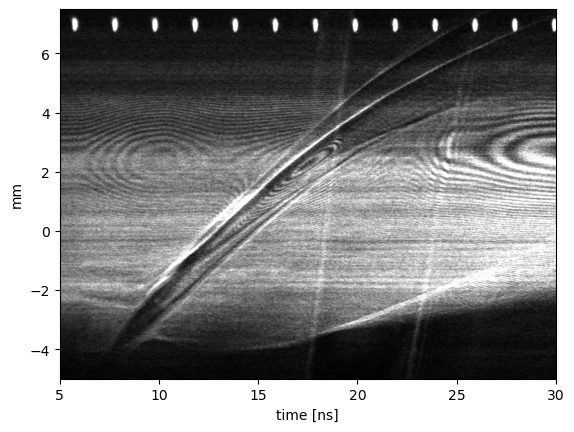

In [7]:
fig, ax = plt.subplots()

extent_x = streak.shape[1] * px_to_ns
extent_y = streak.shape[0] * px_to_mm
ext=[0, extent_x, -extent_y/2, extent_y/2]

plt.imshow(streak, cmap = 'grey', extent=ext, aspect='auto')
plt.clim(0, cmax)
plt.xlabel('time [ns]')
plt.ylabel('mm')

plt.xlim(5, 30)
# plt.xlim(18, 24)
plt.ylim(-5,7.5)


plt.savefig('streak_images/zfs/streak_zoom.jpg', bbox_inches = 'tight')

In [8]:
times_bkgd = np.linspace(3, 5, 51)
times_bkgd = np.array(times_bkgd)
pos_bkgd, lineouts_bkgd = get_lineouts(times_bkgd, bg = np.array([0,0]))

mask = (times_bkgd > 4.0) | (times_bkgd < 3.5)
times_bkgd = times_bkgd[mask]
pos_bkgd = pos_bkgd[mask]
lineouts_bkgd = lineouts_bkgd[mask]

In [9]:
background = np.mean(lineouts_bkgd, axis = 0)

In [10]:
times_shock = np.linspace(10, 30, 21)
pos_shock, lineouts_shock = get_lineouts(times_shock, background)

background subtracting...


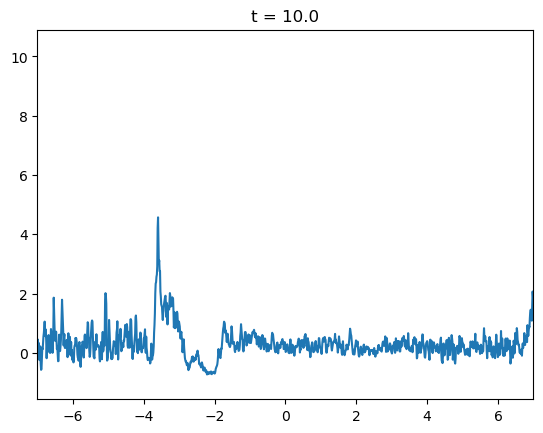

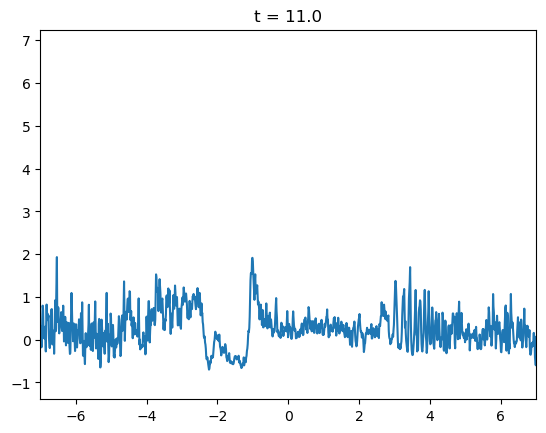

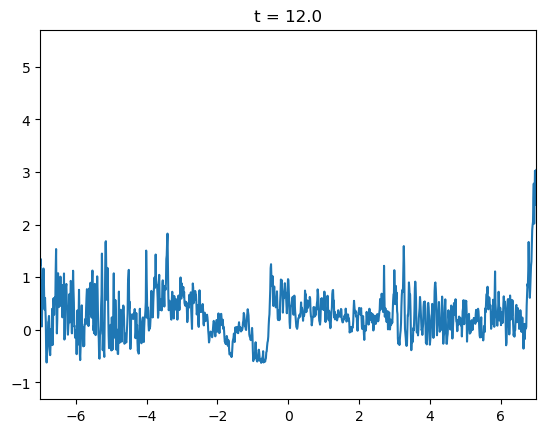

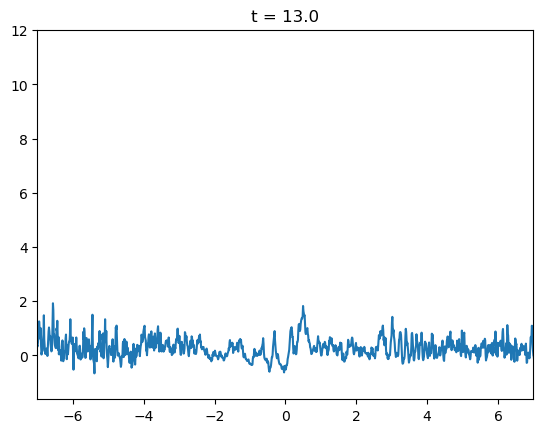

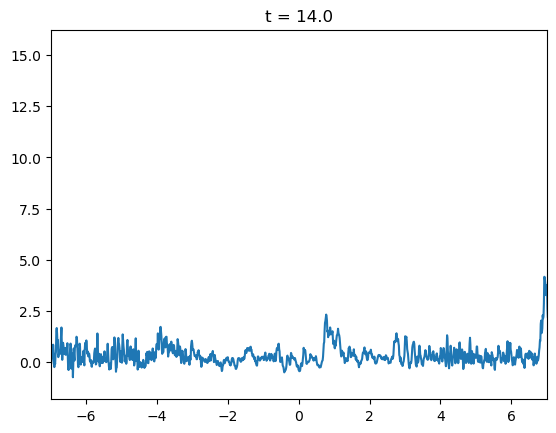

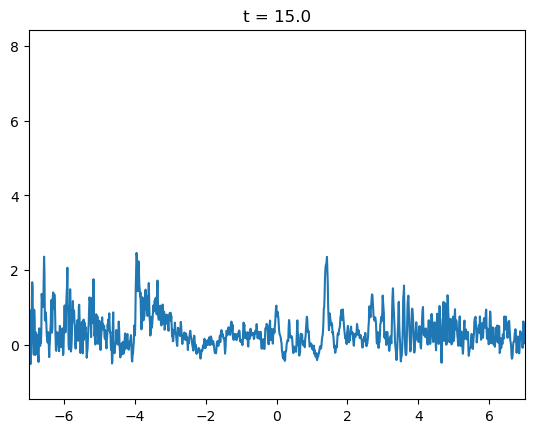

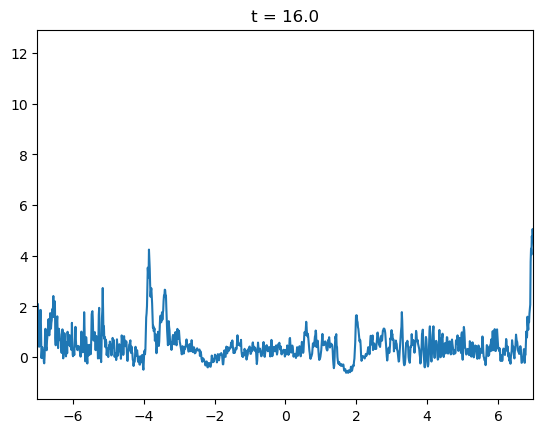

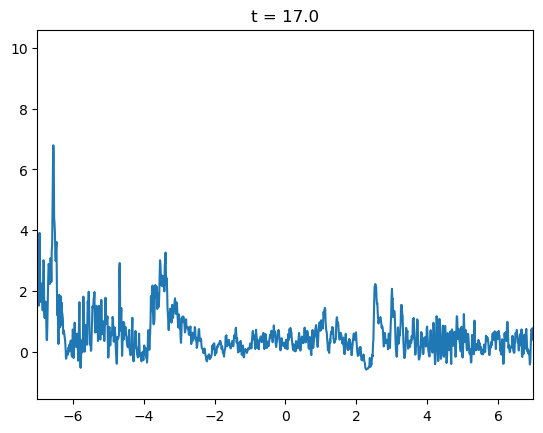

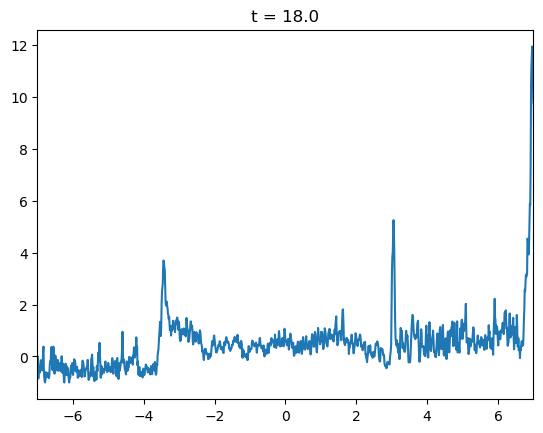

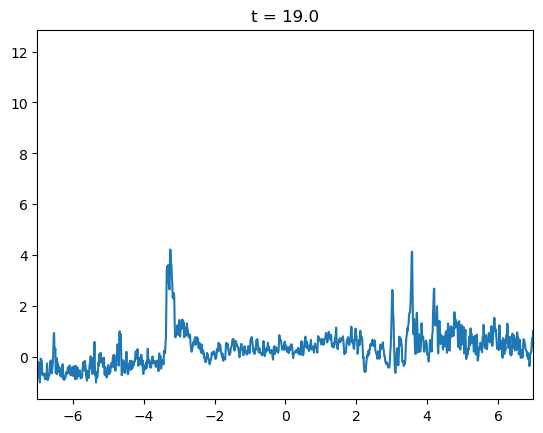

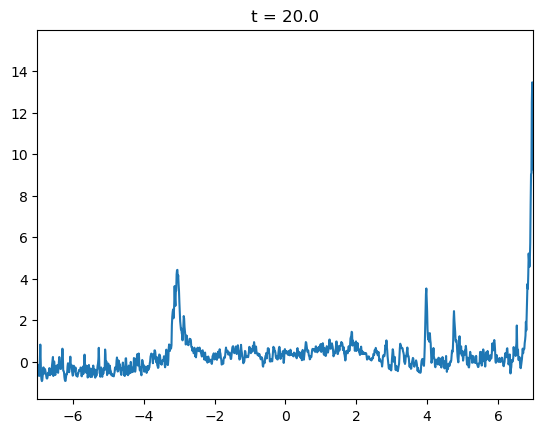

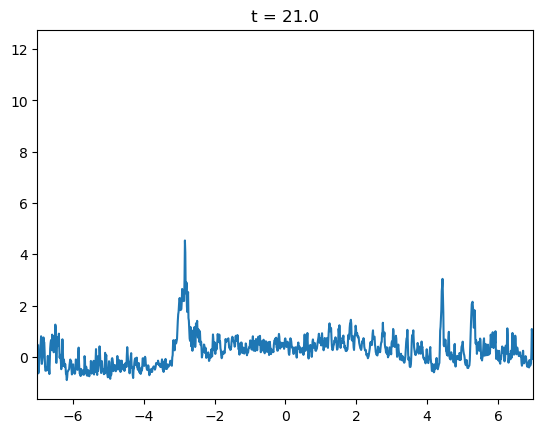

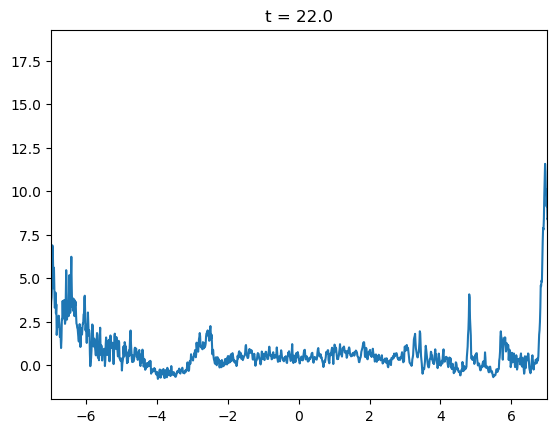

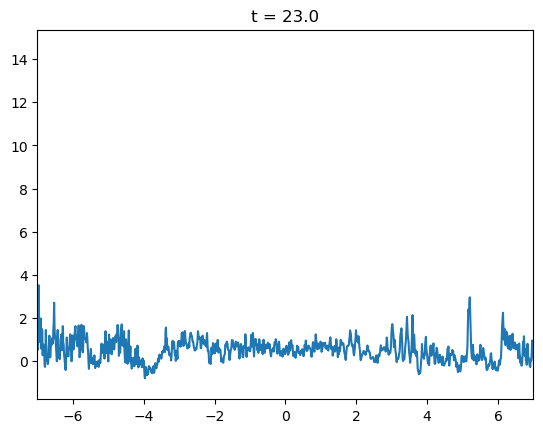

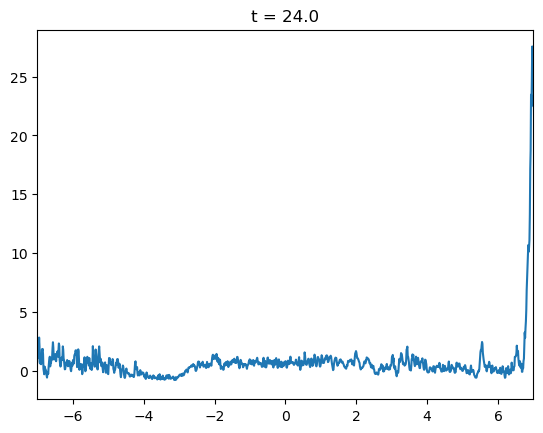

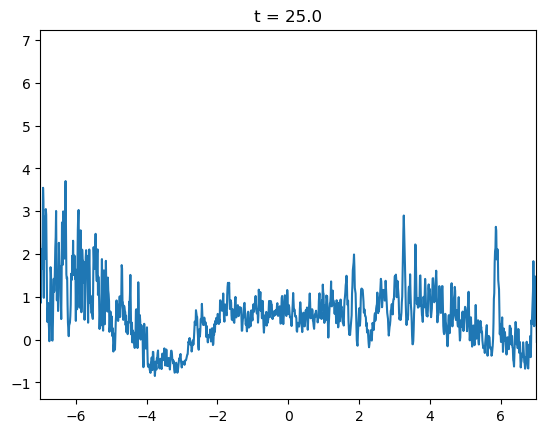

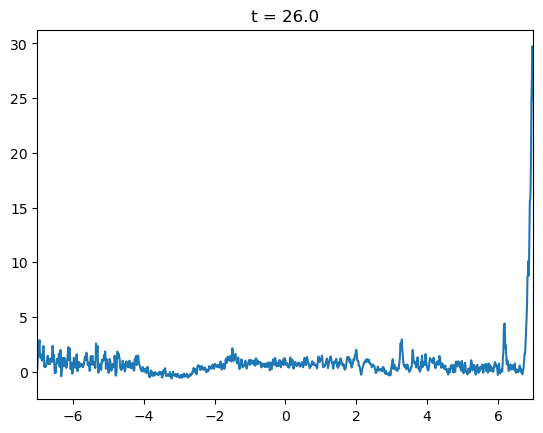

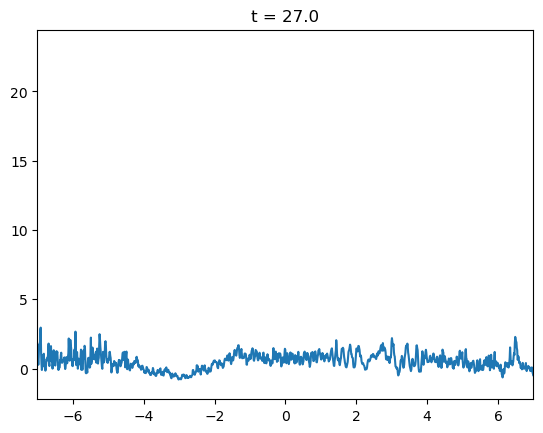

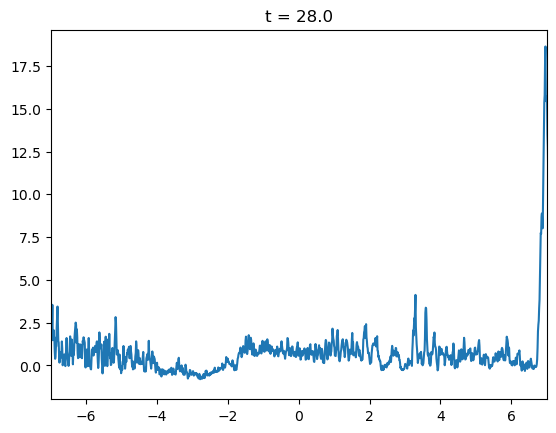

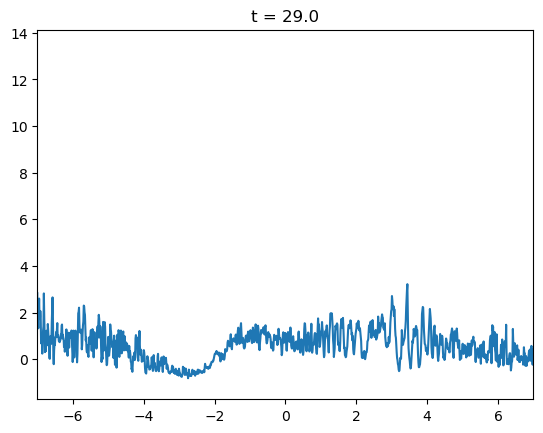

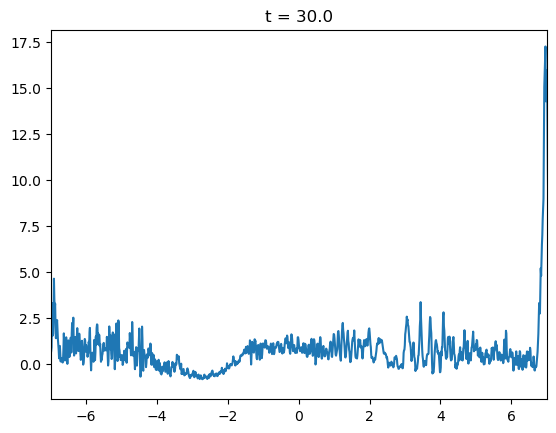

<Figure size 640x480 with 0 Axes>

In [11]:
for i in range(len(times_shock)):
    plt.plot(pos_shock[i], lineouts_shock[i])
    plt.title(f't = {times_shock[i]}')
    plt.xlim(-7,7)
    plt.show()
    plt.clf()

In [12]:
# average lineouts over 2 ns 
times_avg_1618 = np.linspace(16, 18, 51)
pos_avg_1618, lineouts_avg_1618 = get_lineouts(times_avg_1618, background)

background subtracting...


In [13]:
# give common position array for averaged lineouts
pos_shifted_1618 = []
lineouts_shifted_1618 = []
x_common = np.linspace(-2, 2, 1000)

for i in range(len(times_avg_1618)):
    x_data = np.asarray(pos_avg_1618[i], dtype=float)
    y_data = np.asarray(lineouts_avg_1618[i], dtype=float)
    min,max = 1,3.1
    # if (i < 25):
        # min, max = 3.4, 3.7
    mask_piston = (x_data >= min) & (x_data <= max)
    x_fit_p, y_fit_p = x_data[mask_piston],y_data[mask_piston]
    piston_max=(x_fit_p[np.argmax(y_fit_p)])
    print(f'lineout {i}: t = {times_avg_1618[i]}, piston = {piston_max}')

    x_shifted = x_data - piston_max
    sort_idx = np.argsort(x_shifted)
    x_sorted = x_shifted[sort_idx]
    y_sorted = y_data[sort_idx]

    # Interpolate onto common axis
    y_interp = np.interp(x_common, x_sorted, y_sorted)

    # append in descending order for R to L integration
    pos_shifted_1618.append(x_sorted)
    lineouts_shifted_1618.append(y_interp)

lineout 0: t = 16.0, piston = 2.013015710709775
lineout 1: t = 16.04, piston = 2.035320593930935
lineout 2: t = 16.08, piston = 2.0464730355415153
lineout 3: t = 16.12, piston = 2.0576254771520954
lineout 4: t = 16.16, piston = 2.0799303603732575
lineout 5: t = 16.2, piston = 2.113387685204998
lineout 6: t = 16.24, piston = 2.693314648955182
lineout 7: t = 16.28, piston = 2.693314648955182
lineout 8: t = 16.32, piston = 2.693314648955182
lineout 9: t = 16.36, piston = 2.693314648955182
lineout 10: t = 16.4, piston = 2.7379244153975044
lineout 11: t = 16.44, piston = 2.7490768570080846
lineout 12: t = 16.48, piston = 2.7490768570080846
lineout 13: t = 16.52, piston = 2.7490768570080846
lineout 14: t = 16.56, piston = 2.7490768570080846
lineout 15: t = 16.6, piston = 2.336436517416608
lineout 16: t = 16.64, piston = 2.3587414006377685
lineout 17: t = 16.68, piston = 2.381046283858929
lineout 18: t = 16.72, piston = 2.3921987254695107
lineout 19: t = 16.76, piston = 2.403351167080091
line

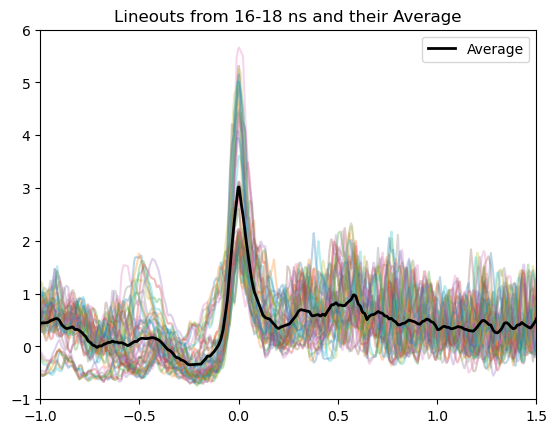

In [14]:
N_lines = 51
for i in range(N_lines):
    plt.plot(x_common, lineouts_shifted_1618[i], alpha=0.3)

average_r0 = np.mean(lineouts_shifted_1618[:N_lines], axis=0)

plt.plot(x_common, average_r0, color='black', linewidth=2, label='Average')
plt.xlim(-1,1.5)
plt.ylim(-1,6)
plt.title('Lineouts from 16-18 ns and their Average')
plt.legend()
plt.show()

In [15]:
# average lineouts over 2 ns 
times_avg = np.linspace(18, 20, 51)
pos_avg, lineouts_avg = get_lineouts(times_avg, background)

background subtracting...


In [16]:
# give common position array for averaged lineouts
pos_shifted_1820 = []
lineouts_shifted_1820 = []
x_common = np.linspace(-2, 2, 1000)

for i in range(len(times_avg)):
    x_data = np.asarray(pos_avg[i], dtype=float)
    y_data = np.asarray(lineouts_avg[i], dtype=float)
    min,max = 3,6
    if (i == 22 or i == 23 or i == 27):
        min, max = 3.4, 3.7
    mask_piston = (x_data >= min) & (x_data <= max)
    x_fit_p, y_fit_p = x_data[mask_piston],y_data[mask_piston]
    piston_max=(x_fit_p[np.argmax(y_fit_p)])
    # print(f'lineout {i}: t = {times_r1[i]}, piston = {piston_max}')

    x_shifted = x_data - piston_max
    sort_idx = np.argsort(x_shifted)
    x_sorted = x_shifted[sort_idx]
    y_sorted = y_data[sort_idx]

    # Interpolate onto common axis
    y_interp = np.interp(x_common, x_sorted, y_sorted)

    # append in descending order for R to L integration
    pos_shifted_1820.append(x_sorted)
    lineouts_shifted_1820.append(y_interp)

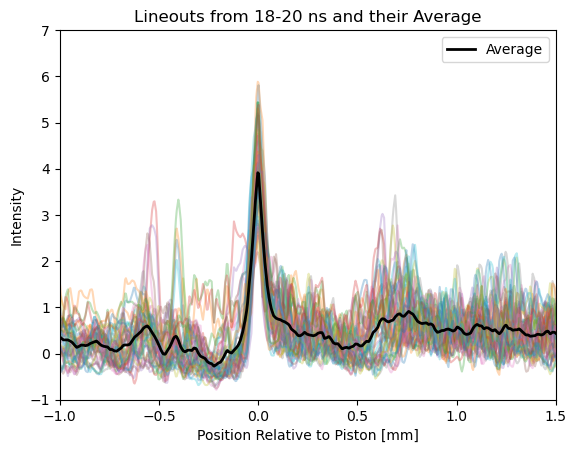

In [17]:
N_lines = 51
for i in range(N_lines):
    plt.plot(x_common, lineouts_shifted_1820[i], alpha=0.3)

average_r1 = np.mean(lineouts_shifted_1820[:N_lines], axis=0)

plt.plot(x_common, average_r1, color='black', linewidth=2, label='Average')
plt.xlim(-1,1.5)
plt.ylim(-1,7)
plt.title('Lineouts from 18-20 ns and their Average')
plt.legend()
plt.ylabel('Intensity')
plt.xlabel('Position Relative to Piston [mm]')
plt.savefig('streak_images/zfs/lineouts_1820', bbox_inches = 'tight')

In [18]:
# average lineouts over 2 ns 
times_avg_2022 = np.linspace(20, 22, 51)
pos_avg_2022, lineouts_avg_2022 = get_lineouts(times_avg_2022, background)

background subtracting...


In [19]:
# give common position array for averaged lineouts
pos_shifted_2022 = []
lineouts_shifted_2022 = []
x_common = np.linspace(-2, 2, 1000)

for i in range(len(times_avg)):
    x_data = np.asarray(pos_avg_2022[i], dtype=float)
    y_data = np.asarray(lineouts_avg_2022[i], dtype=float)
    min,max = 3,4.9
    # if (i == 22 or i == 23 or i == 27):
    #     min, max = 3.4, 3.7
    mask_piston = (x_data >= min) & (x_data <= max)
    x_fit_p, y_fit_p = x_data[mask_piston],y_data[mask_piston]
    piston_max=(x_fit_p[np.argmax(y_fit_p)])
    # print(f'lineout {i}: t = {times_avg_2022[i]}, piston = {piston_max}')

    x_shifted = x_data - piston_max
    sort_idx = np.argsort(x_shifted)
    x_sorted = x_shifted[sort_idx]
    y_sorted = y_data[sort_idx]

    # Interpolate onto common axis
    y_interp = np.interp(x_common, x_sorted, y_sorted)

    # append in descending order for R to L integration
    pos_shifted_2022.append(x_sorted)
    lineouts_shifted_2022.append(y_interp)

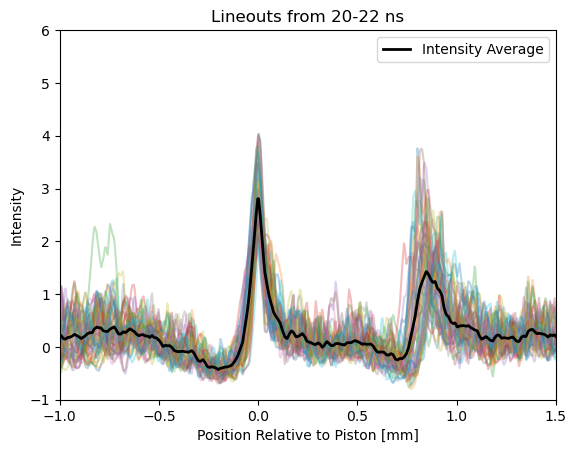

In [20]:
N_lines = 51
for i in range(N_lines):
    plt.plot(x_common, lineouts_shifted_2022[i], alpha=0.3)

average_r2 = np.mean(lineouts_shifted_2022[:N_lines], axis=0)

plt.plot(x_common, average_r2, color='black', linewidth=2, label='Intensity Average')
plt.xlim(-1,1.5)
plt.ylim(-1,6)
plt.title('Lineouts from 20-22 ns')
plt.legend()
plt.ylabel('Intensity')
plt.xlabel('Position Relative to Piston [mm]')
plt.savefig('streak_images/zfs/lineouts_2022', bbox_inches = 'tight')

# Model Shocks

In [21]:
wavelength_um = 0.532 # 0.532 microns
m = 1 # magnification = 1
n_c = 1.1e21/(wavelength_um**2)
L = 4.16 # 4160 mm to first lens

dens_corr = (2*m*n_c)/L
print('critical density:', n_c)
print('correction factor:', dens_corr)

critical density: 3.8865961897224254e+21
correction factor: 1.8685558604434736e+21


In [38]:
def plot_densities_avg(x, y_raw, piston_lim, mag_lim, title):

    path_length = 0.5 #0.5 cm
    
    # make mask for piston based on min and max positions
    mask_piston = (x >= piston_lim[0]) & (x <= piston_lim[1])
    x_piston, y_piston = x[mask_piston], y_raw[mask_piston]
    
    p0_piston = [
        0, 0.05, -200,  # Negative dip
        -0.3, 0.05,  350   # Positive peak
    ]
    
    popt_piston, _ = curve_fit(double_gaussian, x_piston, y_piston, p0=p0_piston)
    
    # make mask for magshock based on min and max positions
    mask_mag = (x >= mag_lim[0]) & (x <= mag_lim[1])
    x_mag, y_mag = x[mask_mag], y_raw[mask_mag]
    
    magshock_min = x_mag[np.argmin(y_mag)]
    magshock_max = x_mag[np.argmax(y_mag)]
    
    p0_mag = [
        magshock_min, 0.05, -200,  # Negative dip (Note the negative amplitude!)
        magshock_max, 0.05,  200   # Positive peak
    ]
    
    popt_mag, _ = curve_fit(double_gaussian, x_mag, y_mag, p0=p0_mag)
    
    # combine fits and mask to spatial windows - make everywhere else equal to 0
    y_fit_piston = np.where(mask_piston, double_gaussian(x, *popt_piston), 0.0)
    y_fit_mag    = np.where(mask_mag,    double_gaussian(x, *popt_mag),    0.0)
    
    # get total fit by summing
    y_fit_total = y_fit_piston + y_fit_mag

    x_cm = x/10
    
    # integrate twice
    dn_dx = cumulative_trapezoid(y_fit_total, x_cm, initial=0) 
    density_pi = dens_corr * cumulative_trapezoid(dn_dx, x_cm, initial=0)
    density = (1/path_length)*dens_corr * cumulative_trapezoid(dn_dx, x_cm, initial=0)

    mask_raw = (x < 1) & (x > -1)
    x_0, y_0 = x[mask_raw], y_raw[mask_raw]
    x_cm_0 = x_0/10
    dn_dx_0 = cumulative_trapezoid(y_0, x_cm_0, initial=0) 
    density_pi_0 = dens_corr * cumulative_trapezoid(dn_dx_0, x_cm_0, initial=0)
    
    # plot
    fig, axs = plt.subplots(3, 1, figsize=(8, 10), sharex=True)
    
    # top: raw data and fit
    axs[0].plot(x, y_raw, color='brown', alpha=0.4, label='Raw Lineout')
    axs[0].plot(x, y_fit_total, color='cornflowerblue', linewidth=2.5, label='Combined 2-Feature Fit')
    axs[0].set_title(f'Lineout Fit: {title}')
    axs[0].set_ylabel('Intensity')
    axs[0].set_xlim(-2, 2)
    axs[0].legend()
    axs[0].grid(True)
    
    # middle: first integration (dn/dx)
    axs[1].plot(x, dn_dx, color='blue', linewidth=2)
    axs[1].set_title('$dn/dx$ Profile')
    axs[1].set_ylabel('dn/dx')
    axs[1].ticklabel_format(axis='y', style='sci', scilimits=(0, 0), useMathText=True)
    axs[1].grid(True)
    
    # bottom: second integration: density
    axs[2].plot(x, density_pi, color='green', linewidth=2, label = 'Path Integrated Density')
    # axs[2].plot(x, density, color='green', linewidth=2, label = 'Density, Path Length = 0.1 cm')
    axs[2].set_title('Path Integrated Density Profile')
    axs[2].set_ylabel(r'Electron Density [cm$^{-3}$]')
    axs[2].set_xlabel('Position Relative to Piston Shock [mm]')
    axs[2].ticklabel_format(axis='y', style='sci', scilimits=(0, 0), useMathText=True)
    # axs[2].set_ylim(-5e18, 2e19)
    axs[2].grid(True)
    
    plt.tight_layout()
    plt.savefig(f'streak_images/zfs/{title}.jpg', bbox_inches = 'tight')

    plt.clf()

    fig, axs = plt.subplots(figsize=(7, 5))
    # plt.plot(x, density, color='green', linewidth=2, label = 'Density')
    plt.plot(x_0, density_pi_0, color='orangered', linewidth=2, label = 'Raw Path Integrated Density', alpha = 0.5, linestyle = '--')
    plt.plot(x, density_pi, color='royalblue', linewidth=2, label = 'Fit Path Integrated Density')
    plt.title(f'Path Integrated Electron Density Profile: {title}')
    plt.grid(True)
    plt.legend()
    plt.ticklabel_format(axis='y', style='sci', scilimits=(0, 0), useMathText=True)
    plt.xlabel('Position Relative to Piston Shock [mm]')
    plt.ylabel(r'Path Integrated Density [cm$^{-2}$]')
    plt.savefig(f'streak_images/zfs/dens_{title}.jpg', bbox_inches = 'tight')

    fig, axs = plt.subplots(figsize=(7, 5))
    # plt.plot(x, density, color='green', linewidth=2, label = 'Density')
    plt.plot(x, density_pi, color='green', linewidth=2, label = 'Fit Path Integrated Density')
    plt.title(f'Path Integrated Electron Density Profile: {title}')
    plt.grid(True)
    plt.ticklabel_format(axis='y', style='sci', scilimits=(0, 0), useMathText=True)
    plt.xlabel('Position Relative to Piston Shock [mm]')
    plt.ylabel(r'Path Integrated Density [cm$^{-2}$]')
    plt.savefig(f'streak_images/zfs/dens_{title}_clean.jpg', bbox_inches = 'tight')

    fig, axs = plt.subplots(figsize=(7, 5))
    plt.plot(x, y_raw, color='orangered', alpha=0.6, label='Raw Lineout')
    plt.plot(x, y_fit_total, color='royalblue', linewidth=2.5, label='Combined Gaussian Fit')
    plt.title(f'Lineout Fit: {title}')
    plt.xlim(-2, 2)
    plt.legend()
    plt.grid(True)
    plt.xlabel('Position Relative to Piston Shock [mm]')
    plt.ylabel(r'Intensity')
    plt.savefig(f'streak_images/zfs/intensity_{title}.jpg', bbox_inches = 'tight')
    
    fig, axs = plt.subplots(figsize=(7, 5))
    plt.plot(x_0, dn_dx_0, color='orangered', linewidth=2, alpha = 0.5, linestyle = '--', label = 'Raw Data Integration')
    plt.plot(x, dn_dx, color='royalblue', linewidth=2, label = 'Fit Integration')
    plt.title(r'First Integration: $\frac{dn_e}{dx}$ Profile')
    plt.ylabel('dn/dx')
    plt.xlabel('Position Relative to Piston Shock [mm]')
    plt.ticklabel_format(axis='y', style='sci', scilimits=(0, 0), useMathText=True)
    plt.grid(True)
    plt.legend()
    plt.savefig(f'streak_images/zfs/dndx_{title}.jpg', bbox_inches = 'tight')

In [39]:
def plot_densities_gate(x, y_raw, piston_lim, mag_lim, peaks, title):

    path_length = 0.5 # path length in cm 
    
    # make mask for piston based on min and max positions
    mask_piston = (x >= peaks[0]-piston_lim[0]) & (x <= peaks[1]+piston_lim[1])
    x_piston, y_piston = x[mask_piston], y_raw[mask_piston]

    piston_min = x_piston[np.argmin(y_piston)]
    piston_max = x_piston[np.argmax(y_piston)]
    
    p0_piston = [
        piston_min, 0.5, -2,  # Negative dip
        piston_max, 0.2,  4   # Positive peak
    ]
    
    popt_piston, _ = curve_fit(double_gaussian, x_piston, y_piston, p0=p0_piston, maxfev = 10000)
    
    # make mask for magshock based on min and max positions
    mask_mag = (x >= peaks[2]-mag_lim[0]) & (x <= peaks[3]+mag_lim[1])
    x_mag, y_mag = x[mask_mag], y_raw[mask_mag]
    
    magshock_min = x_mag[np.argmin(y_mag)]
    magshock_max = x_mag[np.argmax(y_mag)]
    
    p0_mag = [
        magshock_min, 0.05, -2,  # Negative dip (Note the negative amplitude!)
        magshock_max, 0.05,  4   # Positive peak
    ]
    
    popt_mag, _ = curve_fit(double_gaussian, x_mag, y_mag, p0=p0_mag, maxfev = 10000)
    
    # combine fits and mask to spatial windows - make everywhere else equal to 0
    y_fit_piston = np.where(mask_piston, double_gaussian(x, *popt_piston), 0.0)
    y_fit_mag    = np.where(mask_mag,    double_gaussian(x, *popt_mag),    0.0)
    
    # get total fit by summing
    y_fit_total = y_fit_piston + y_fit_mag

    x_cm = x/10.0
    
    # integrate twice
    dn_dx = cumulative_trapezoid(y_fit_total, x_cm, initial=0) 
    density_pi = dens_corr * cumulative_trapezoid(dn_dx, x_cm, initial=0)
    density = (1/path_length)*dens_corr * cumulative_trapezoid(dn_dx, x_cm, initial=0)

    mask_raw = (x < 1) & (x > -1)
    x_0, y_0 = x_0[mask_raw], y_raw[mask_raw]
    x_cm_0 = x_0/10

    dn_dx_0 = cumulative_trapezoid(y_0, x_cm_0, initial=0) 
    density_pi_0 = dens_corr * cumulative_trapezoid(dn_dx_0, x_cm_0, initial=0)
    
    # plot
    fig, axs = plt.subplots(3, 1, figsize=(8, 10), sharex=True)
    
    # top: raw data and fit
    axs[0].plot(x, y_raw, color='coral', alpha=0.4, label='Raw Lineout')
    axs[0].plot(x, y_fit_total, color='dodgerblue', linewidth=2.5, label='Combined 2-Feature Fit')
    axs[0].set_title(f'Lineout Fit: {title}')
    axs[0].set_ylabel('Intensity')
    axs[0].set_xlim(0, 5)
    axs[0].legend()
    axs[0].grid(True)
    
    # middle: first integration (dn/dx)
    axs[1].plot(x, dn_dx, color='blue', linewidth=2)
    axs[1].plot(x, dn_dx, color='orange', linewidth=2)
    axs[1].set_title('$dn/dx$ Profile')
    axs[1].set_ylabel('dn/dx')
    axs[1].ticklabel_format(axis='y', style='sci', scilimits=(0, 0), useMathText=True)
    axs[1].grid(True)
    
    # bottom: second integration: density
    axs[2].plot(x, density, color='green', linewidth=2, label = 'Density, Path Length = 0.1 cm')
    axs[2].set_title('Density Profile')
    axs[2].set_ylabel(f'Density [cm$^{-3}$]')
    axs[2].set_xlabel('Position Relative to Piston Shock [mm]')
    axs[2].legend()
    # axs[2].set_ylim(-5e18, 2e19)
    axs[2].grid(True)
    
    plt.tight_layout()
    # plt.savefig(f'streak_images/new_dens/t={times_shock_late[i]}_shift={shift:.2f}.jpg')

In [40]:
def find_shock_positions(x_data, y_data, times, piston_lim, mag_lim):
    plt.plot(x_data, y_data, color = 'brown', label = f'Lineout', alpha = 0.8)
    
    mask_piston = (x_data >= piston_lim[0]) & (x_data <= piston_lim[1])
    x_fit_p, y_fit_p = x_data[mask_piston],y_data[mask_piston]
    piston_max=(x_fit_p[np.argmax(y_fit_p)])
    piston_min=(x_fit_p[np.argmin(y_fit_p)])
    
    mask_mag = (x_data >= mag_lim[0]) & (x_data <= mag_lim[1])
    x_fit, y_fit = x_data[mask_mag],y_data[mask_mag]
    
    magshock_max = x_fit[np.argmax(y_fit)]
    magshock_min = x_fit[np.argmin(y_fit)]
    
    plt.axvline(magshock_max, color = 'seagreen', label = 'MagShock Max')
    plt.axvline(magshock_min, color = 'limegreen', label = 'MagShock Min')
    
    plt.axvline(piston_max, color = 'deepskyblue', label = 'Piston Max')
    plt.axvline(piston_min, color = 'powderblue', label = 'Piston Min')
        
    plt.xlim(0,8)
    plt.xlim(piston_max-1,piston_max+1.5)
    plt.legend(loc = 'upper left')
    plt.ylim(-1,5)
    plt.title(f'Shock Lineout at t = {times}')
    plt.xlabel('Position [mm]')
    plt.ylabel('Intensity')
    plt.savefig(f'streak_images/lineouts/peaks/t={times}.jpg', bbox_inches = 'tight') 
    plt.clf()

    peaks = [piston_min, piston_max, magshock_min, magshock_max]

    return peaks

shift: 0.508


<Figure size 800x1000 with 0 Axes>

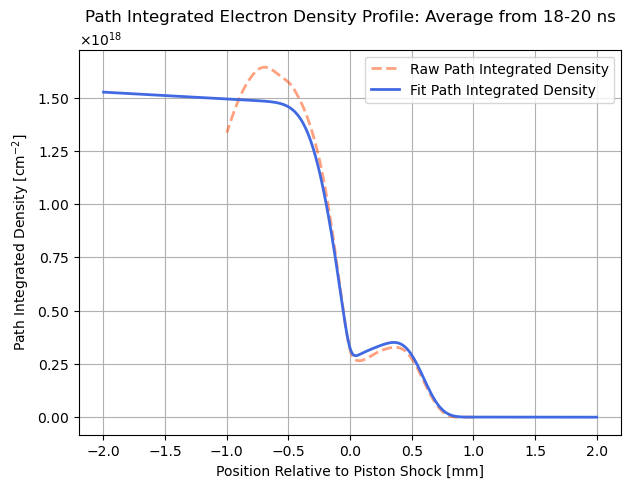

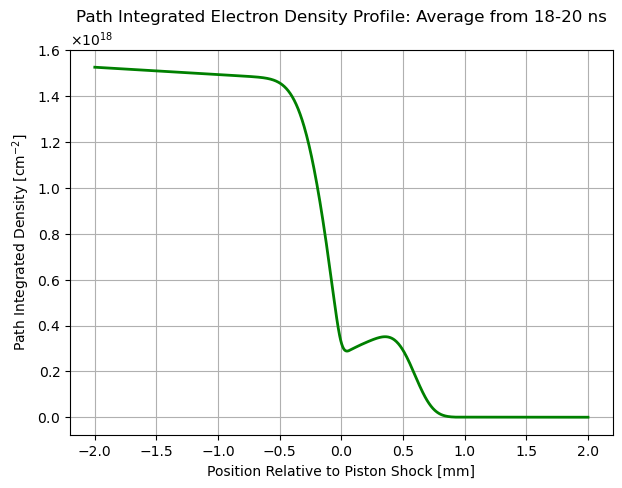

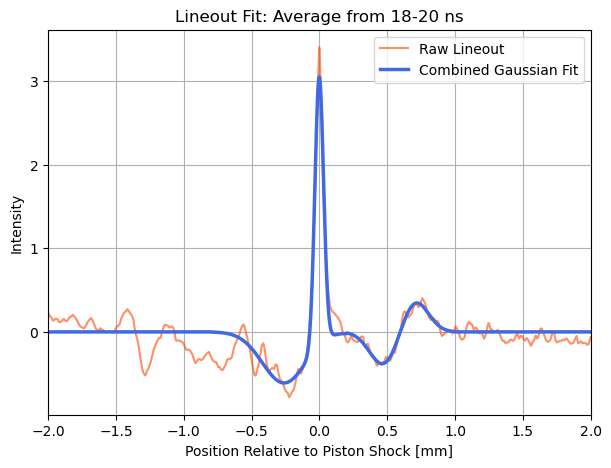

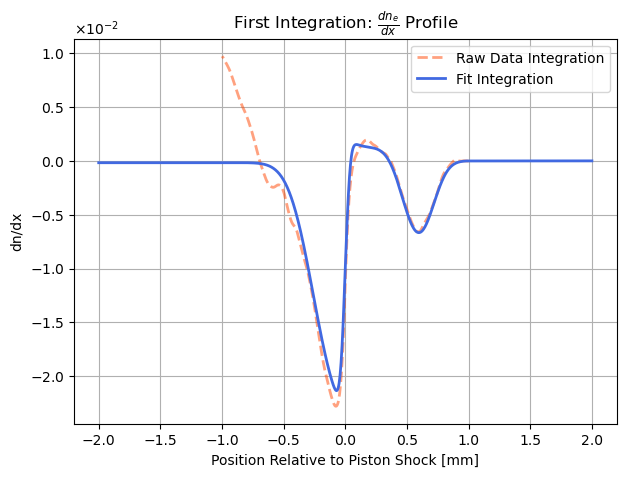

In [41]:
shift = 0.508
print('shift:', shift)

y_raw = average_r1 - shift
sort_descending = np.argsort(x_common)[::-1] 

x_data = x_common[sort_descending]
y_data = y_raw[sort_descending]

piston_lim = [-0.8, 0.2]
mag_lim = [0.1, 1]

plot_densities_avg(x_data, y_data, piston_lim, mag_lim, 'Average from 18-20 ns')

shift: 0.256


<Figure size 800x1000 with 0 Axes>

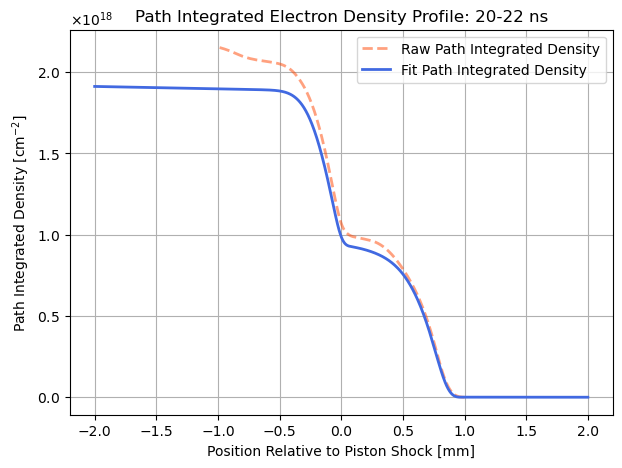

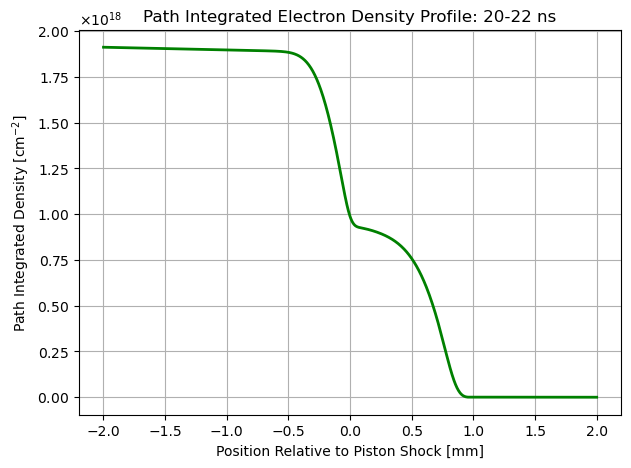

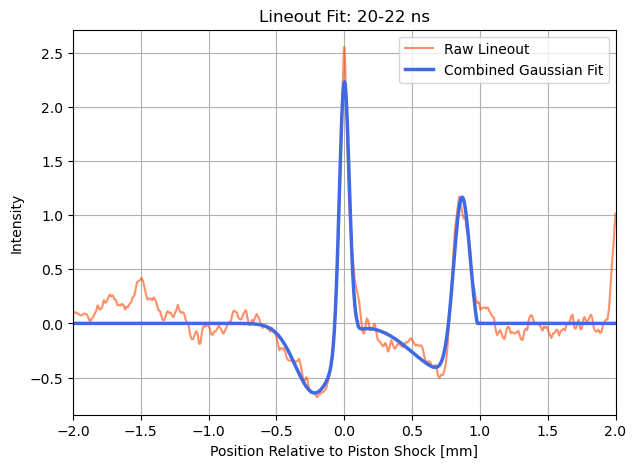

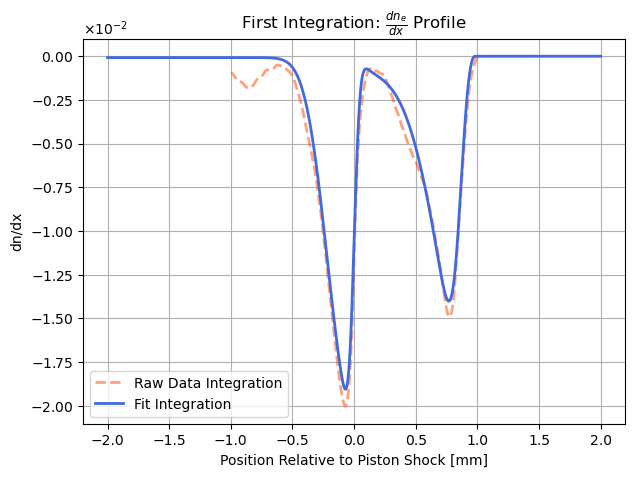

In [42]:
shift = 0.256
print('shift:', shift)

y_raw = average_r2 - shift
sort_descending = np.argsort(x_common)[::-1] 

x_data = x_common[sort_descending]
y_data = y_raw[sort_descending]

piston_lim = [-0.8, 0.3]
mag_lim = [0.1, 0.98]

plot_densities_avg(x_data, y_data, piston_lim, mag_lim, '20-22 ns')

In [43]:
all_peaks = []
peak_times = []

# t = 15
i = 5
piston_lims = [0.5, 2]
mag_lims = [1.5, 2]
peaks_15 = find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_15)
peak_times.append(times_shock[i])

# t = 16
i = 6
piston_lims = [1, 3]
mag_lims = [2.3, 2.55]
peaks_16 = find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_16)
peak_times.append(times_shock[i])

i = 7
piston_lims = [1, 4]
mag_lims = [2.8, 3.05]
peaks_17 = find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_17)
peak_times.append(times_shock[i])

i = 8
piston_lims = [1, 4]
mag_lims = [3.4, 4]
peaks_18 = find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_18)
peak_times.append(times_shock[i])

i = 9
piston_lims = [3.2, 4]
mag_lims = [3.7, 4.5]
peaks_19 = find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_19)
peak_times.append(times_shock[i])

i = 10
piston_lims = [3.2, 4]
mag_lims = [4.5, 5]
peaks_20 = find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_20)
peak_times.append(times_shock[i])

i = 11
piston_lims = [4, 5]
mag_lims = [5, 6]
peaks_21 = find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_21)
peak_times.append(times_shock[i])

i = 12
piston_lims = [4, 5]
mag_lims = [5, 6]
peaks_22 = find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_22)
peak_times.append(times_shock[i])

i = 13
piston_lims = [4.5, 5.5]
mag_lims = [5.5, 6.5]
peaks_23 = find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_23)
peak_times.append(times_shock[i])

i = 14
piston_lims = [4.5, 5.5]
mag_lims = [6, 6.7]
peaks_24 = find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_24)
peak_times.append(times_shock[i])

i = 15
piston_lims = [5, 6]
mag_lims = [6, 7]
peaks_25 = find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_25)
peak_times.append(times_shock[i])

i = 17
piston_lims = [6.4, 6.5]
mag_lims = [7.4, 8]
peaks_26 = find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_26)
peak_times.append(times_shock[i])

all_peaks = np.array(all_peaks)

<Figure size 640x480 with 0 Axes>

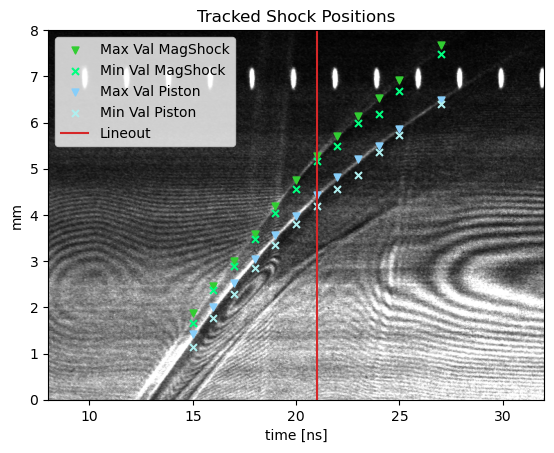

In [44]:
plt.imshow(streak, cmap = 'grey', extent=ext, aspect='auto')
plt.clim(0, cmax)
plt.xlabel('time [ns]')
plt.ylabel('mm')

plt.scatter(peak_times, all_peaks[:,3], color = 'limegreen', s = 25, label = 'Max Val MagShock', marker = 'v')
plt.scatter(peak_times, all_peaks[:,2], color = 'springgreen', s = 25, label = 'Min Val MagShock', marker = 'x')
plt.scatter(peak_times, all_peaks[:,1], color = 'lightskyblue', s = 25, label = 'Max Val Piston', marker = 'v')
plt.scatter(peak_times, all_peaks[:,0], color = 'paleturquoise', s = 25, label = 'Min Val Piston', marker = 'x')

plt.axvline(21, color = 'tab:red', label = 'Lineout')

plt.xlim(8, 32)
plt.ylim(0, 8)
# plt.ylim(1, 5)
plt.legend(loc = 'upper left')
plt.title('Tracked Shock Positions')

plt.savefig('streak_images/zfs/shock_positions_img_ROI', bbox_inches = 'tight')

In [45]:
rel_pos_magshock = []
speeds_magshock = []
for i in range(len(peak_times)-1):
    j = i+1
    rel = all_peaks[j,3] - all_peaks[j-1,3]
    rel_pos_r1.append(peak_times[j]) 
    speed_mm_ns = rel/(peak_times[j]-peak_times[j-1])
    speed_km_s = speed_mm_ns * (1e-6)/(1e-9)
    speeds_magshock.append(speed_km_s)
    print(peak_times[j])
    print(speed_km_s)

rel_pos_piston = []
speeds_piston = []
for i in range(len(peak_times)-1):
    j = i+1
    rel = all_peaks[j,1] - all_peaks[j-1,1]
    rel_pos_piston.append(peak_times[j]) 
    speed_mm_ns = rel/(peak_times[j]-peak_times[j-1])
    speed_km_s = speed_mm_ns * (1e-6)/(1e-9)
    speeds_piston.append(speed_km_s)

NameError: name 'rel_pos_r1' is not defined

In [ ]:
times_plot = [15.5, 16.5, 17.5, 18.5, 19.5, 20.5, 21.5, 22.5, 23.5, 24.5, 26]
print(times_plot)
plt.scatter(times_plot, speeds_magshock, label = 'Mag Shock', color = 'skyblue')
plt.scatter(times_plot, speeds_piston, label = 'Piston Shock', color = 'limegreen')
plt.legend()
plt.title('Shock Speeds')
plt.ylabel('Speed [km/s]')
plt.xlabel('Time [ns]')
plt.savefig('streak_images/zfs/speeds', bbox_inches = 'tight')

In [ ]:
i = 8

x_data = pos_shock[i]
shift = 0.628
y_data = lineouts_shock[i] - shift
piston_lim = [0.35, 0.0325]
mag_lim = [0.1, 0.05]

plot_densities_gate(x_data, y_data, piston_lim, mag_lim, peaks_18, 't = 18 ns')

In [ ]:
i = 9

x_data = pos_shock[i]
shift = 1
y_data = lineouts_shock[i] - shift
piston_lim = [0.15, 0.0325]
mag_lim = [0.1, 0.05]

plot_densities_gate(x_data, y_data, piston_lim, mag_lim, peaks_19, 't = 19 ns')